c:\Users\Pc\Documents\tess-transit-project\.venv\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 18 data products.

 #      mission     year author exptime target_name distance
                                   s                 arcsec 
--- --------------- ---- ------ ------- ----------- --------
  0  TESS Sector 02 2018   SPOC     120   100100827      0.0
  1  TESS Sector 03 2018   SPOC     120   100100827      0.0
  2  TESS Sector 29 2020   SPOC      20   100100827      0.0
  3  TESS Sector 30 2020   SPOC      20   100100827      0.0
  4  TESS Sector 29 2020   SPOC     120   100100827      0.0
  5  TESS Sector 30 2020   SPOC     120   100100827      0.0
  6  TESS Sector 69 2023   SPOC      20   100100827      0.0
  7  TESS Sector 69 2023   SPOC     120   100100827      0.0
  8  TESS Sector 96 2025   SPOC      20   100100827      0.0
  9  TESS Sector 96 2025   SPOC     120   100100827      0.0
 10 TESS Sector 103 2026   SPOC      20   100100827      0.0
 11 TESS Sector 104 2026   SPOC      20   100100827      0.0
 12 TESS Sector 105 2026   SPOC      20   

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

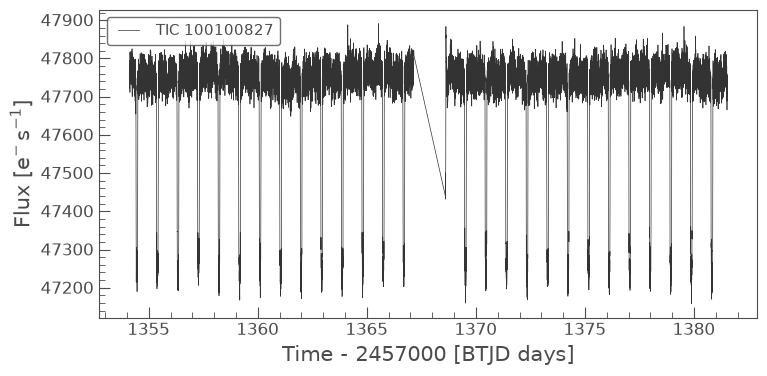

In [1]:
import lightkurve as lk

search = lk.search_lightcurve("WASP-18", mission="TESS", author="SPOC")
print(search)

lc = search[0].download()
lc.plot()

In [2]:
# Καθαρισμός: αφαιρούμε κενές τιμές και κάνουμε τη φωτεινότητα σχετική (μέσος όρος = 1)
lc_clean = lc.remove_nans().normalize()

# Αφαιρούμε τις αργές μεταβολές του άστρου, κρατώντας τις γρήγορες βυθίσεις
lc_flat = lc_clean.flatten(window_length=901)
lc_flat.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

In [3]:
import numpy as np

# Ψάχνουμε περιόδους από 0,5 έως 3 μέρες με τη μέθοδο BLS (Box Least Squares)
periods = np.linspace(0.5, 3, 10000)
bls = lc_flat.to_periodogram(method="bls", period=periods)
bls.plot()

period = bls.period_at_max_power
t0 = bls.transit_time_at_max_power
duration = bls.duration_at_max_power
print("Περίοδος:", period)
print("Χρόνος διάβασης:", t0)
print("Διάρκεια:", duration)

# "Διπλώνουμε" την καμπύλη πάνω στην περίοδο
lc_flat.fold(period=period, epoch_time=t0).scatter()

Περίοδος: 0.9415441544154415 d
Χρόνος διάβασης: 1354.4515072617191
Διάρκεια: 0.1 d


<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

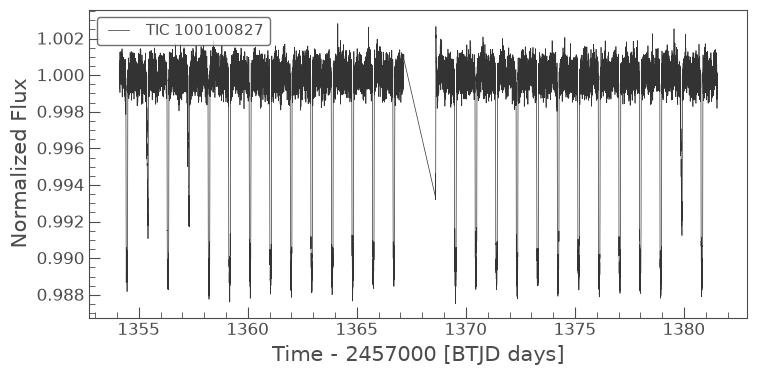

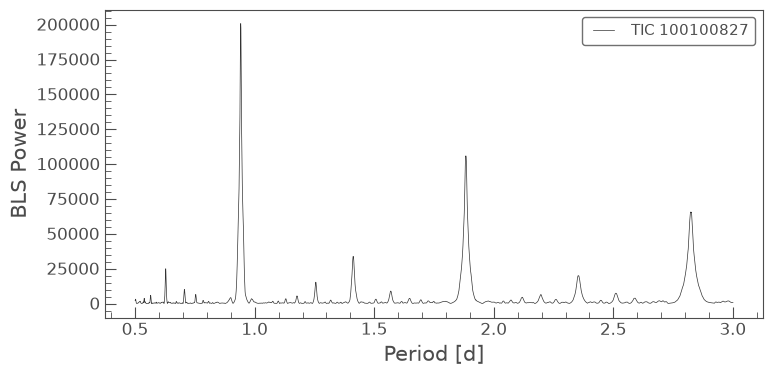

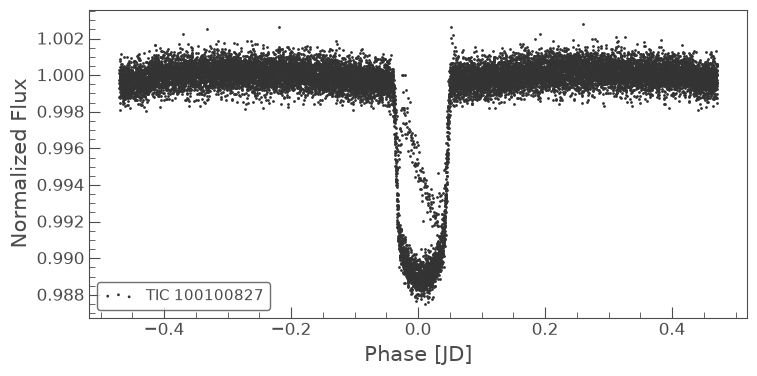

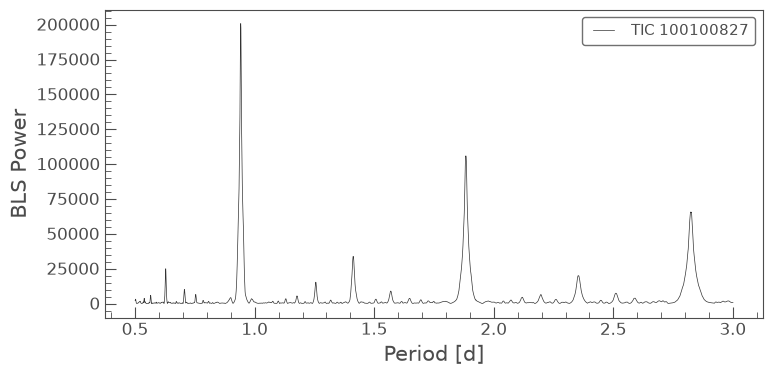

In [4]:
import matplotlib.pyplot as plt
bls.plot()
plt.show()

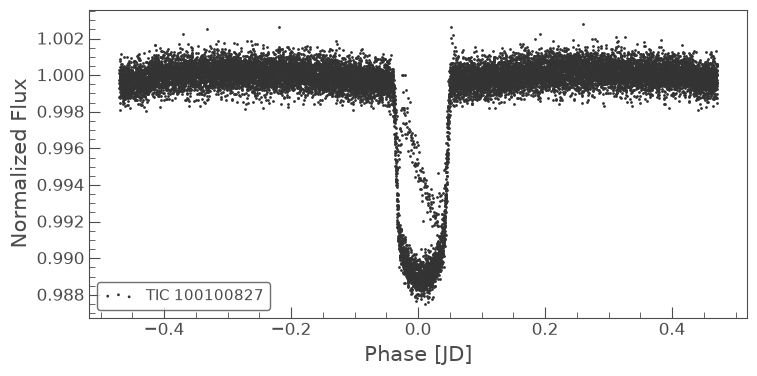

In [5]:
import matplotlib.pyplot as plt
lc_flat.fold(period=period, epoch_time=t0).scatter()
plt.show()

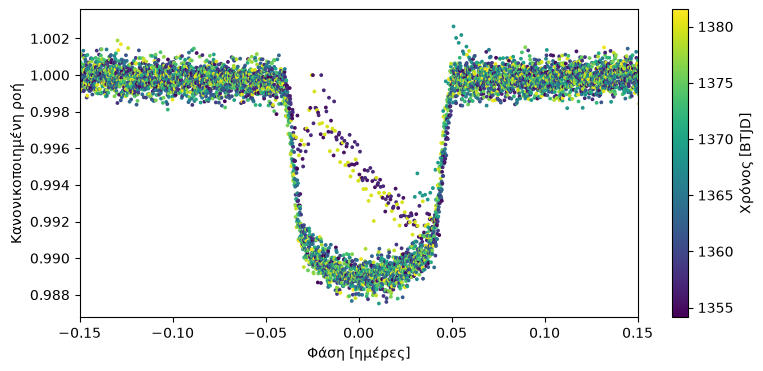

In [6]:
import matplotlib.pyplot as plt
folded = lc_flat.fold(period=period, epoch_time=t0)
plt.figure(figsize=(9, 4))
sc = plt.scatter(folded.time.value, folded.flux.value,
                 c=folded.time_original.value, s=3, cmap="viridis")
plt.colorbar(sc, label="Χρόνος [BTJD]")
plt.xlim(-0.15, 0.15)
plt.xlabel("Φάση [ημέρες]")
plt.ylabel("Κανονικοποιημένη ροή")
plt.show()

Σημεία μέσα σε διάβαση: 2884 από 18299


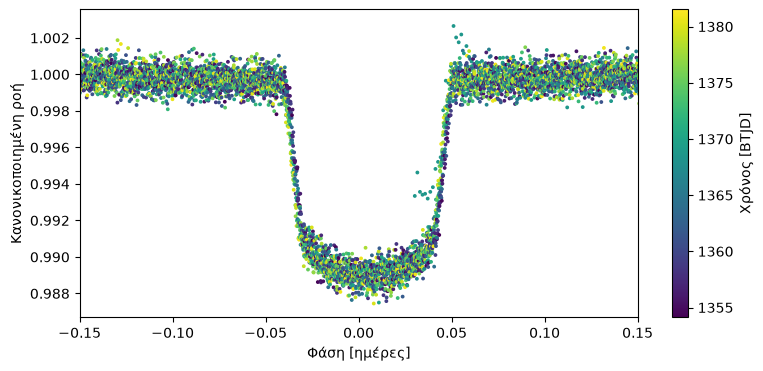

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# απλοί αριθμοί αντί για "masked" πίνακες
t = lc_clean.time.value
t = np.asarray(getattr(t, "unmasked", t), dtype=float)
P = float(period.value)    # περίοδος σε ημέρες
T0 = float(t0.value)       # χρόνος διάβασης σε BTJD
dur = 0.15                 # πλάτος μάσκας σε ημέρες (η διάβαση κρατά ~0,09)

# True για τα σημεία μέσα σε διάβαση
transit_mask = np.abs((t - T0 + P/2) % P - P/2) < dur/2
print("Σημεία μέσα σε διάβαση:", transit_mask.sum(), "από", len(t))

# ίσιωσε την καμπύλη αγνοώντας αυτά τα σημεία
lc_flat2 = lc_clean.flatten(window_length=901, mask=transit_mask)

folded2 = lc_flat2.fold(period=period, epoch_time=t0)
plt.figure(figsize=(9, 4))
sc = plt.scatter(folded2.time.value, folded2.flux.value,
                 c=folded2.time_original.value, s=3, cmap="viridis")
plt.colorbar(sc, label="Χρόνος [BTJD]")
plt.xlim(-0.15, 0.15)
plt.xlabel("Φάση [ημέρες]")
plt.ylabel("Κανονικοποιημένη ροή")
plt.show()

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def arr(q):
    v = getattr(q, "value", q)
    v = getattr(v, "unmasked", v)
    return np.asarray(v, dtype=float)

f = lc_flat2.fold(period=period, epoch_time=t0)
ph = arr(f.time)            # φάση σε ημέρες
fl = arr(f.flux)
er = arr(f.flux_err)
to = arr(f.time_original)   # πραγματικός χρόνος κάθε σημείου

keep = (np.abs(ph) < 0.15) & np.isfinite(fl) & ~((to > 1368) & (to < 1369.5))
x, y, yerr = ph[keep], fl[keep], er[keep]
print("Σημεία για το fit:", len(x))

Σημεία για το fit: 5619


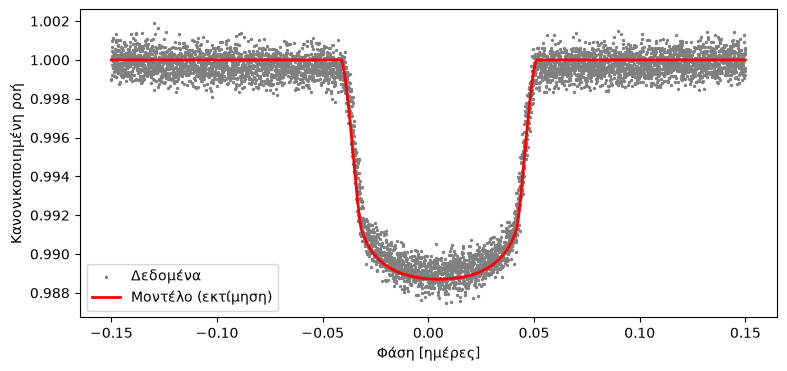

In [9]:
P = float(period.value)
u1, u2 = 0.2192, 0.3127   # limb darkening, Claret (2017), όπως στο Shporer et al. (2019)

# 600 σημεία που καλύπτουν ομοιόμορφα τον δίσκο του πλανήτη
n = 600
i = np.arange(n) + 0.5
rr = np.sqrt(i / n)
th = np.pi * (1 + 5**0.5) * i
px, py = rr * np.cos(th), rr * np.sin(th)

def transit_model(ph, dt0, k, a, b):
    phi = 2 * np.pi * (ph - dt0) / P
    X = a * np.sin(phi)
    Y = b * np.cos(phi)
    z = np.sqrt(X**2 + Y**2)                 # απόσταση κέντρων σε ακτίνες άστρου
    xs = z[:, None] + k * px[None, :]
    ys = k * py[None, :]
    r2 = xs**2 + ys**2
    mu = np.sqrt(np.clip(1 - r2, 0, None))
    I = 1 - u1 * (1 - mu) - u2 * (1 - mu)**2  # φωτεινότητα άστρου σε κάθε σημείο
    blocked = (I * (r2 < 1)).sum(axis=1) * (np.pi * k**2 / n)
    F0 = np.pi * (1 - u1 / 3 - u2 / 6)        # συνολικό φως άστρου
    flux = 1 - blocked / F0
    flux[np.cos(phi) < 0] = 1.0               # πίσω από το άστρο: καμία διάβαση
    return flux

guess = [0.005, 0.10, 3.5, 0.3]   # Δt0, Rp/Rs, a/Rs, b

xs_plot = np.linspace(-0.15, 0.15, 600)
plt.figure(figsize=(9, 4))
plt.scatter(x, y, s=2, color="gray", label="Δεδομένα")
plt.plot(xs_plot, transit_model(xs_plot, *guess), color="red", lw=2, label="Μοντέλο (εκτίμηση)")
plt.xlabel("Φάση [ημέρες]")
plt.ylabel("Κανονικοποιημένη ροή")
plt.legend()
plt.show()

Δt0 [d]  = 0.00525 ± 0.00007
Rp/Rs    = 0.09875 ± 0.00030
a/Rs     = 3.51045 ± 0.06533
b        = 0.32395 ± 0.05550
Κλίση τροχιάς i = 84.71°
Διάρκεια διάβασης = 2.19 ώρες
Νέο T0 = 1354.45676 BTJD
Reduced χ² = 1.22


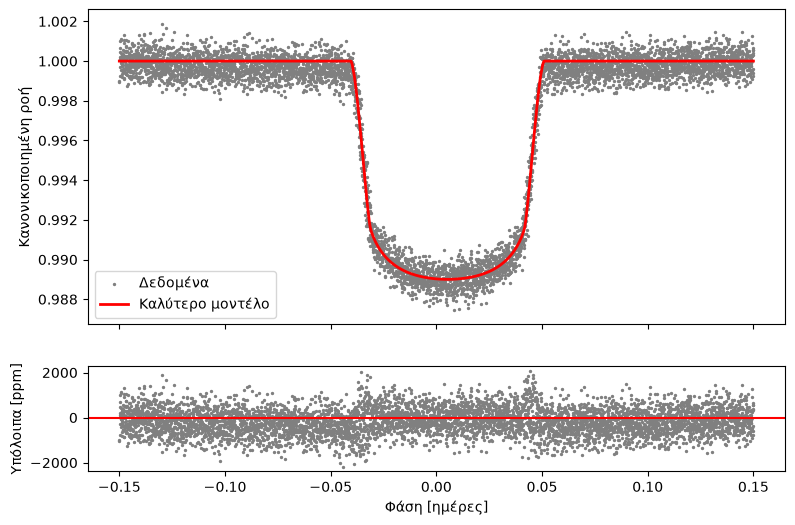

In [10]:
from scipy.optimize import curve_fit

bounds = ([-0.03, 0.05, 1.5, 0.0], [0.03, 0.20, 10.0, 1.0])
popt, pcov = curve_fit(transit_model, x, y, p0=guess, sigma=yerr,
                       absolute_sigma=True, bounds=bounds)
perr = np.sqrt(np.diag(pcov))

names = ["Δt0 [d]", "Rp/Rs", "a/Rs", "b"]
for nm, v, e in zip(names, popt, perr):
    print(f"{nm:8s} = {v:.5f} ± {e:.5f}")

dt0, k, a, b = popt
inc = np.degrees(np.arccos(b / a))
T14 = P / np.pi * np.arcsin(np.sqrt((1 + k)**2 - b**2) / (a * np.sin(np.radians(inc))))
print(f"Κλίση τροχιάς i = {inc:.2f}°")
print(f"Διάρκεια διάβασης = {T14 * 24:.2f} ώρες")
print(f"Νέο T0 = {float(t0.value) + dt0:.5f} BTJD")

resid = y - transit_model(x, *popt)
chi2r = np.sum((resid / yerr)**2) / (len(x) - 4)
print(f"Reduced χ² = {chi2r:.2f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.scatter(x, y, s=2, color="gray", label="Δεδομένα")
ax1.plot(xs_plot, transit_model(xs_plot, *popt), color="red", lw=2, label="Καλύτερο μοντέλο")
ax1.set_ylabel("Κανονικοποιημένη ροή")
ax1.legend()
ax2.scatter(x, resid * 1e6, s=2, color="gray")
ax2.axhline(0, color="red")
ax2.set_ylabel("Υπόλοιπα [ppm]")
ax2.set_xlabel("Φάση [ημέρες]")
plt.show()

T0 [BTJD]  = 1354.456912 ± 0.000029
P [d]      = 0.941523 ± 0.000000
Rp/Rs      = 0.099291 ± 0.000333
a/Rs       = 3.395089 ± 0.066844
b          = 0.407198 ± 0.044124
Reduced χ² = 1.16


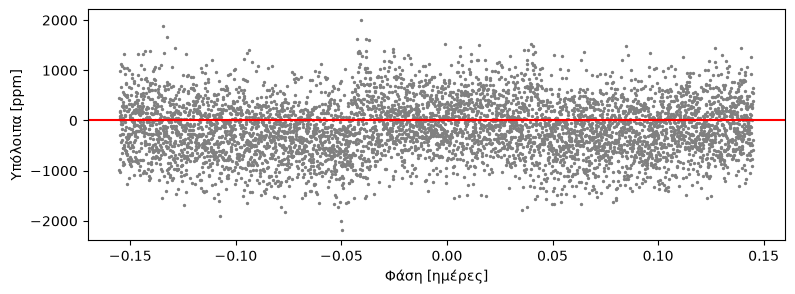

In [11]:
x_t = to[keep]   # πραγματικός χρόνος [BTJD] των ίδιων σημείων

def model_time(t, T0, Pf, k, a, b):
    ph = (t - T0 + Pf/2) % Pf - Pf/2
    return transit_model(ph, 0.0, k, a, b)

p0 = [float(t0.value) + dt0, P, k, a, b]
bounds = ([p0[0] - 0.01, P - 0.001, 0.05, 1.5, 0.0],
          [p0[0] + 0.01, P + 0.001, 0.20, 10.0, 1.0])
popt2, pcov2 = curve_fit(model_time, x_t, y, p0=p0, sigma=yerr,
                         absolute_sigma=True, bounds=bounds)

resid2 = y - model_time(x_t, *popt2)
chi2r2 = np.sum((resid2 / yerr)**2) / (len(y) - 5)
perr2 = np.sqrt(np.diag(pcov2)) * np.sqrt(chi2r2)   # διόρθωση αβεβαιοτήτων

names2 = ["T0 [BTJD]", "P [d]", "Rp/Rs", "a/Rs", "b"]
for nm, v, e in zip(names2, popt2, perr2):
    print(f"{nm:10s} = {v:.6f} ± {e:.6f}")
print(f"Reduced χ² = {chi2r2:.2f}")

ph2 = (x_t - popt2[0] + popt2[1]/2) % popt2[1] - popt2[1]/2
plt.figure(figsize=(9, 3))
plt.scatter(ph2, resid2 * 1e6, s=2, color="gray")
plt.axhline(0, color="red")
plt.xlabel("Φάση [ημέρες]")
plt.ylabel("Υπόλοιπα [ppm]")
plt.show()

In [12]:
k, a, b = popt[1], popt[2], popt[3]   # σχήμα διάβασης από το κελί 3

tt = arr(lc_flat2.time); ff = arr(lc_flat2.flux); ee = arr(lc_flat2.flux_err)
good = np.isfinite(ff)
tt, ff, ee = tt[good], ff[good], ee[good]

T0g = float(t0.value) + dt0
ep_min = int(np.floor((tt.min() - T0g) / P))
ep_max = int(np.ceil((tt.max() - T0g) / P))
shifts = np.arange(-0.01, 0.01, 0.00005)

epochs, times, errs = [], [], []
for ep in range(ep_min, ep_max + 1):
    tc = T0g + ep * P
    sel = np.abs(tt - tc) < 0.12
    ts, fs, es = tt[sel], ff[sel], ee[sel]
    if len(ts) < 100 or ts.min() > tc - 0.08 or ts.max() < tc + 0.08:
        continue   # λείπει κομμάτι της διάβασης
    chi = np.array([np.sum(((fs - transit_model(ts - tc - s, 0.0, k, a, b)) / es)**2)
                    for s in shifts])
    j = np.argmin(chi)
    if j < 2 or j > len(shifts) - 3:
        continue
    c2, c1, c0 = np.polyfit(shifts[j-2:j+3], chi[j-2:j+3], 2)
    epochs.append(ep)
    times.append(tc - c1 / (2 * c2))
    errs.append(1 / np.sqrt(c2))

epochs = np.array(epochs); times = np.array(times); errs = np.array(errs)
print("Διαβάσεις που μετρήθηκαν:", len(epochs))

Διαβάσεις που μετρήθηκαν: 27


P  = 0.9414599 ± 0.0000032 d
T0 = 1354.457785 ± 0.000052 BTJD


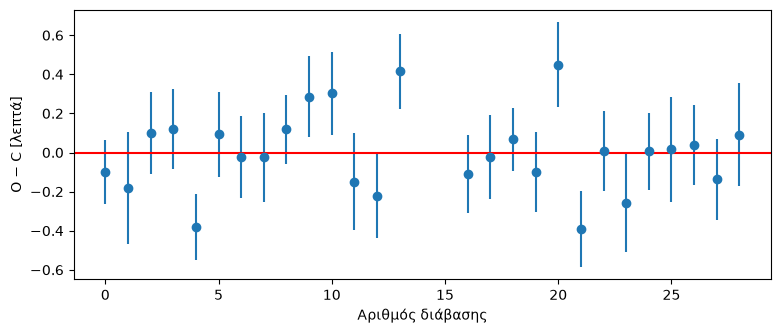

In [13]:
coef, cov = np.polyfit(epochs, times, 1, w=1/errs, cov="unscaled")
P_new, T0_new = coef
P_err, T0_err = np.sqrt(np.diag(cov))
print(f"P  = {P_new:.7f} ± {P_err:.7f} d")
print(f"T0 = {T0_new:.6f} ± {T0_err:.6f} BTJD")

oc = (times - (T0_new + P_new * epochs)) * 24 * 60   # σε λεπτά
plt.figure(figsize=(9, 3.5))
plt.errorbar(epochs, oc, yerr=errs * 24 * 60, fmt="o")
plt.axhline(0, color="red")
plt.xlabel("Αριθμός διάβασης")
plt.ylabel("O − C [λεπτά]")
plt.show()

Rp/Rs  = 0.09877 ± 0.00007
a/Rs   = 3.50663 ± 0.00362
b      = 0.32456 ± 0.00202
i = 84.69°   Διάρκεια = 2.20 ώρες   Reduced χ² = 1.11


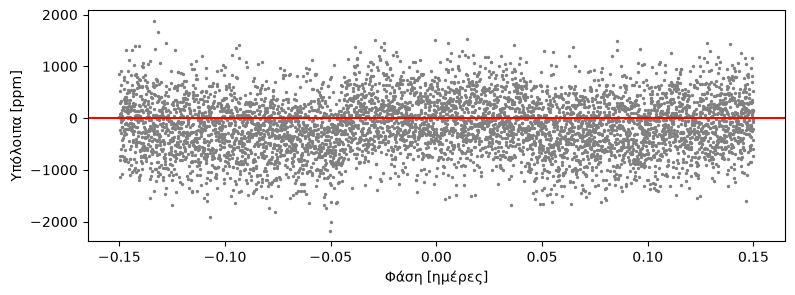

In [14]:
P = P_new
ph = (tt - T0_new + P/2) % P - P/2
sel = (np.abs(ph) < 0.15) & ~((tt > 1368) & (tt < 1369.5))
x, y, yerr = ph[sel], ff[sel], ee[sel]

def shape_model(ph, k, a, b):
    return transit_model(ph, 0.0, k, a, b)

popt3, pcov3 = curve_fit(shape_model, x, y, p0=[k, a, b], sigma=yerr,
                         absolute_sigma=True, diff_step=1e-3,
                         bounds=([0.05, 1.5, 0.0], [0.20, 10.0, 1.0]))
resid3 = y - shape_model(x, *popt3)
chi2r3 = np.sum((resid3 / yerr)**2) / (len(x) - 3)
perr3 = np.sqrt(np.diag(pcov3)) * np.sqrt(chi2r3)

k3, a3, b3 = popt3
inc3 = np.degrees(np.arccos(b3 / a3))
T14 = P / np.pi * np.arcsin(np.sqrt((1 + k3)**2 - b3**2) / (a3 * np.sin(np.radians(inc3))))
for nm, v, e in zip(["Rp/Rs", "a/Rs", "b"], popt3, perr3):
    print(f"{nm:6s} = {v:.5f} ± {e:.5f}")
print(f"i = {inc3:.2f}°   Διάρκεια = {T14 * 24:.2f} ώρες   Reduced χ² = {chi2r3:.2f}")

plt.figure(figsize=(9, 3))
plt.scatter(x, resid3 * 1e6, s=2, color="gray")
plt.axhline(0, color="red")
plt.xlabel("Φάση [ημέρες]")
plt.ylabel("Υπόλοιπα [ppm]")
plt.show()

In [15]:
%pip install emcee corner

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import time

sel2 = np.abs(x) < 0.07
xm, ym = x[sel2], y[sel2]
em = yerr[sel2] * np.sqrt(chi2r3)   # διόρθωση αβεβαιοτήτων σημείων

t_start = time.time()
for _ in range(20):
    shape_model(xm, *popt3)
dt = (time.time() - t_start) / 20
print("Σημεία:", len(xm))
print(f"Χρόνος ανά υπολογισμό: {dt*1000:.1f} ms")
print(f"Εκτίμηση για 36.000 υπολογισμούς: {dt*36000/60:.1f} λεπτά")

Σημεία: 2626
Χρόνος ανά υπολογισμό: 292.0 ms
Εκτίμηση για 36.000 υπολογισμούς: 175.2 λεπτά


Σημεία μετά τη συμπίεση: 201
Χρόνος ανά υπολογισμό: 3.40 ms
Εκτίμηση για 36.000 υπολογισμούς: 2.0 λεπτά
Μέγιστη διαφορά παλιού-νέου μοντέλου: 31 ppm


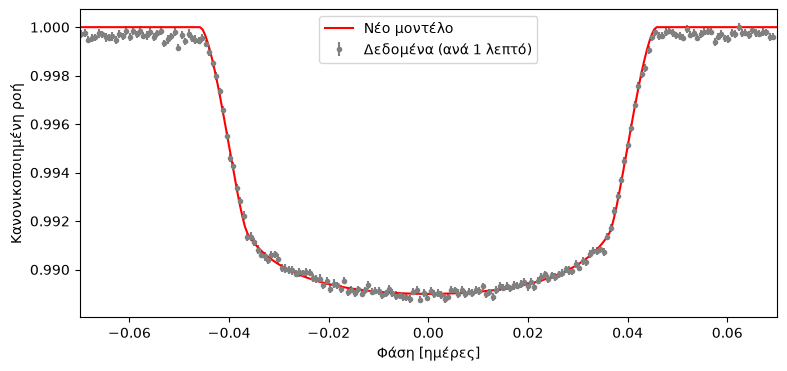

In [17]:
# 1. Μέσος όρος ανά 1 λεπτό φάσης
edges = np.arange(-0.07, 0.07 + 1e-9, 1/1440)
idx = np.digitize(xm, edges) - 1
xb, yb, eb = [], [], []
for j in range(len(edges) - 1):
    s = idx == j
    if s.sum() >= 3:
        xb.append(xm[s].mean())
        yb.append(ym[s].mean())
        eb.append(np.sqrt(np.sum(em[s]**2)) / s.sum())
xb, yb, eb = np.array(xb), np.array(yb), np.array(eb)

# 2. Μοντέλο με δαχτυλίδια
Nr = 100
frac = (np.arange(Nr) + 0.5) / Nr

def transit_model2(ph, k, a, b):
    phi = 2 * np.pi * ph / P
    z = np.sqrt((a * np.sin(phi))**2 + (b * np.cos(phi))**2)
    flux = np.ones_like(ph)
    on = (z < 1 + k) & (np.cos(phi) > 0)     # μόνο όσα είναι σε διάβαση
    zz = z[on]
    lo = np.clip(zz - k, 0, 1)
    hi = np.clip(zz + k, 0, 1)
    r = lo[:, None] + frac[None, :] * (hi - lo)[:, None]   # ακτίνες δαχτυλιδιών
    dr = (hi - lo)[:, None] / Nr
    c = (r**2 + zz[:, None]**2 - k**2) / (2 * r * zz[:, None])
    arc = 2 * r * np.arccos(np.clip(c, -1, 1))             # μήκος που κρύβει ο πλανήτης
    mu = np.sqrt(1 - r**2)
    I = 1 - u1 * (1 - mu) - u2 * (1 - mu)**2
    blocked = np.sum(I * arc * dr, axis=1)
    F0 = np.pi * (1 - u1 / 3 - u2 / 6)
    flux[on] = 1 - blocked / F0
    return flux

# 3. Ταχύτητα
t_start = time.time()
for _ in range(50):
    transit_model2(xb, *popt3)
dt2 = (time.time() - t_start) / 50
print("Σημεία μετά τη συμπίεση:", len(xb))
print(f"Χρόνος ανά υπολογισμό: {dt2*1000:.2f} ms")
print(f"Εκτίμηση για 36.000 υπολογισμούς: {dt2*36000/60:.1f} λεπτά")

# 4. Συμφωνεί με το παλιό μοντέλο;
diff = transit_model2(xs_plot, *popt3) - shape_model(xs_plot, *popt3)
print(f"Μέγιστη διαφορά παλιού-νέου μοντέλου: {np.max(np.abs(diff))*1e6:.0f} ppm")

plt.figure(figsize=(9, 4))
plt.errorbar(xb, yb, yerr=eb, fmt=".", color="gray", label="Δεδομένα (ανά 1 λεπτό)")
plt.plot(xs_plot, transit_model2(xs_plot, *popt3), color="red", label="Νέο μοντέλο")
plt.xlim(-0.07, 0.07)
plt.xlabel("Φάση [ημέρες]")
plt.ylabel("Κανονικοποιημένη ροή")
plt.legend()
plt.show()

Rp/Rs    = 0.09753
a/Rs     = 3.46356
b        = 0.37334
βάση f0  = 0.99967
Η βάση απέχει -332 ppm από το 1
Reduced χ² = 0.77


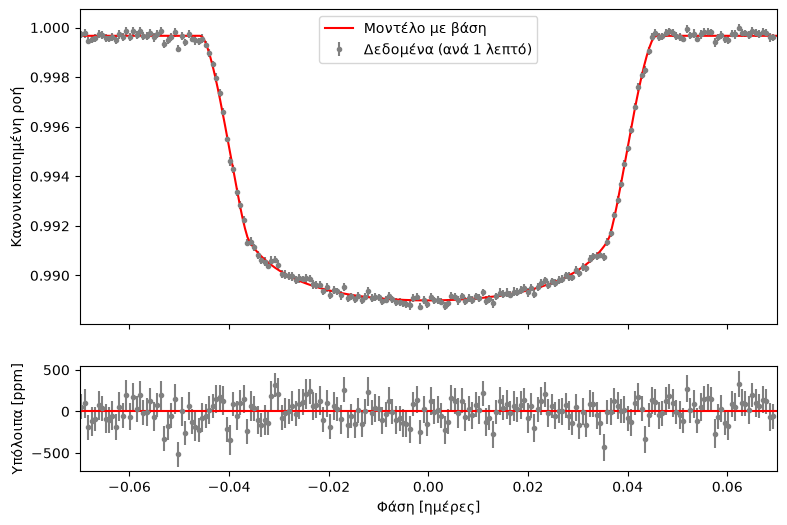

In [18]:
def model_f0(ph, k, a, b, f0):
    return f0 * transit_model2(ph, k, a, b)

p0 = [*popt3, 1.0]
popt4, pcov4 = curve_fit(model_f0, xb, yb, p0=p0, sigma=eb, absolute_sigma=True,
                         bounds=([0.05, 1.5, 0.0, 0.99], [0.20, 10.0, 1.0, 1.01]))
res4 = yb - model_f0(xb, *popt4)
chi2r4 = np.sum((res4 / eb)**2) / (len(xb) - 4)

for nm, v in zip(["Rp/Rs", "a/Rs", "b", "βάση f0"], popt4):
    print(f"{nm:8s} = {v:.5f}")
print(f"Η βάση απέχει {(popt4[3] - 1)*1e6:.0f} ppm από το 1")
print(f"Reduced χ² = {chi2r4:.2f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
ax1.errorbar(xb, yb, yerr=eb, fmt=".", color="gray", label="Δεδομένα (ανά 1 λεπτό)")
ax1.plot(xs_plot, model_f0(xs_plot, *popt4), color="red", label="Μοντέλο με βάση")
ax1.set_xlim(-0.07, 0.07)
ax1.set_ylabel("Κανονικοποιημένη ροή")
ax1.legend()
ax2.errorbar(xb, res4 * 1e6, yerr=eb * 1e6, fmt=".", color="gray")
ax2.axhline(0, color="red")
ax2.set_ylabel("Υπόλοιπα [ppm]")
ax2.set_xlabel("Φάση [ημέρες]")
plt.show()

100%|██████████| 1500/1500 [02:29<00:00, 10.04it/s]


Rp/Rs  = 0.09751  +0.00015 / -0.00015
a/Rs   = 3.46709  +0.02352 / -0.02245
b      = 0.37053  +0.01646 / -0.01733
f0     = 0.99967  +0.00002 / -0.00002
i      = 83.87°  +0.33 / -0.32
Ποσοστό αποδοχής βημάτων: 0.60


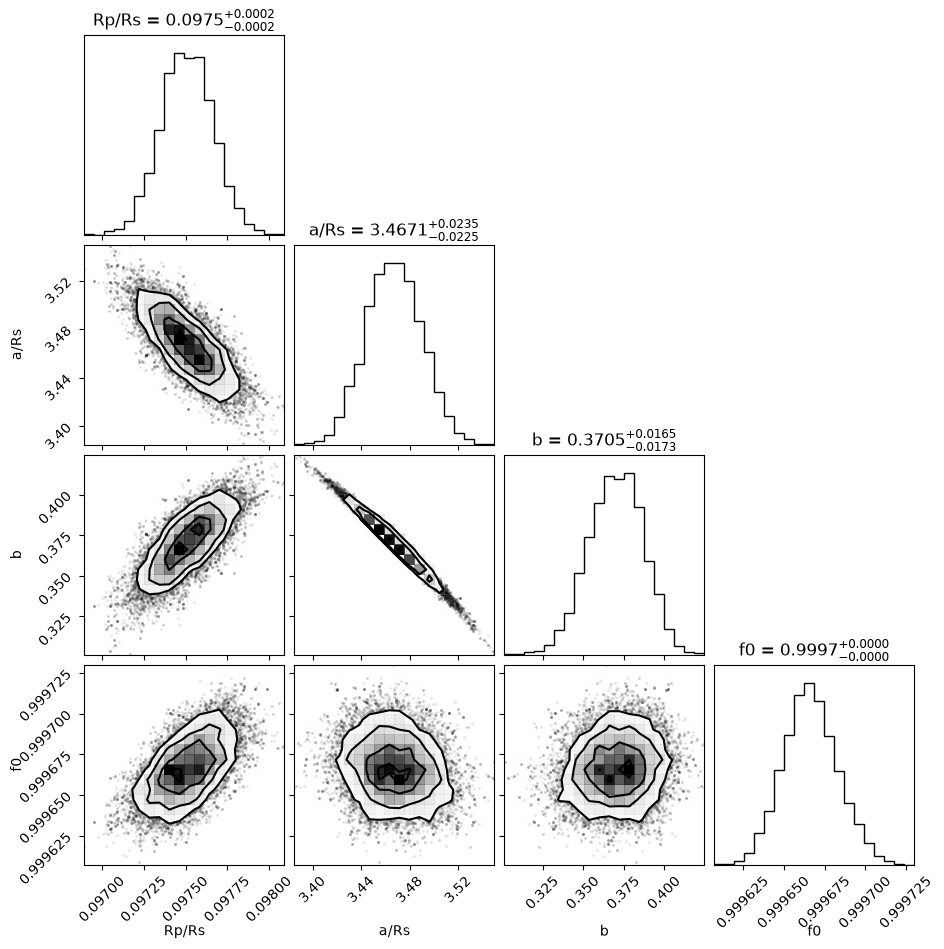

In [19]:
import emcee, corner

eb2 = eb * np.sqrt(chi2r4)   # αβεβαιότητες σημείων ώστε χ² ≈ 1

def log_prob(theta):
    k, a, b, f0 = theta
    if not (0.05 < k < 0.2 and 1.5 < a < 10 and 0 <= b < 1 and 0.99 < f0 < 1.01):
        return -np.inf                     # εκτός λογικών ορίων: απορρίπτεται
    m = model_f0(xb, k, a, b, f0)
    return -0.5 * np.sum(((yb - m) / eb2)**2)   # όσο μεγαλύτερο, τόσο καλύτερο ταίριασμα

ndim, nwalkers, nsteps = 4, 24, 1500
start = popt4 + 1e-5 * np.random.randn(nwalkers, ndim)   # 24 περιπατητές γύρω από το fit
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob)
sampler.run_mcmc(start, nsteps, progress=True)

flat = sampler.get_chain(discard=500, flat=True)   # πετάμε τα πρώτα 500 βήματα («ζέσταμα»)
names = ["Rp/Rs", "a/Rs", "b", "f0"]
for i, nm in enumerate(names):
    lo, med, hi = np.percentile(flat[:, i], [16, 50, 84])
    print(f"{nm:6s} = {med:.5f}  +{hi - med:.5f} / -{med - lo:.5f}")

inc_s = np.degrees(np.arccos(flat[:, 2] / flat[:, 1]))
lo, med, hi = np.percentile(inc_s, [16, 50, 84])
print(f"i      = {med:.2f}°  +{hi - med:.2f} / -{med - lo:.2f}")
print(f"Ποσοστό αποδοχής βημάτων: {np.mean(sampler.acceptance_fraction):.2f}")

corner.corner(flat, labels=names, show_titles=True, title_fmt=".4f")
plt.show()

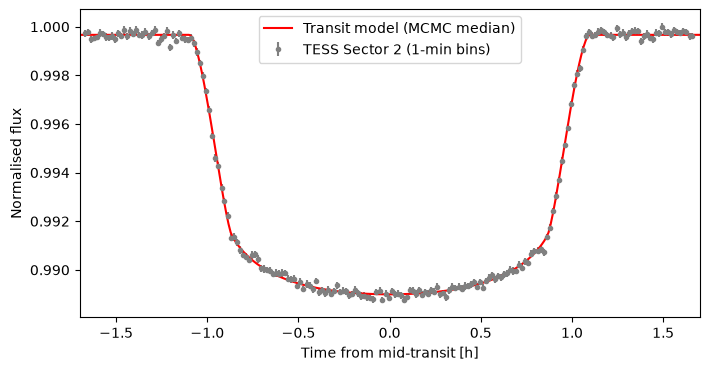

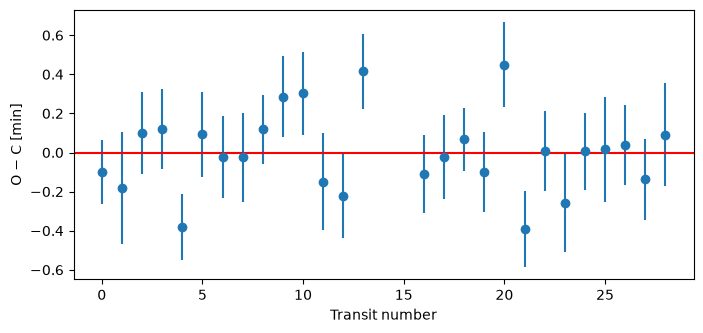

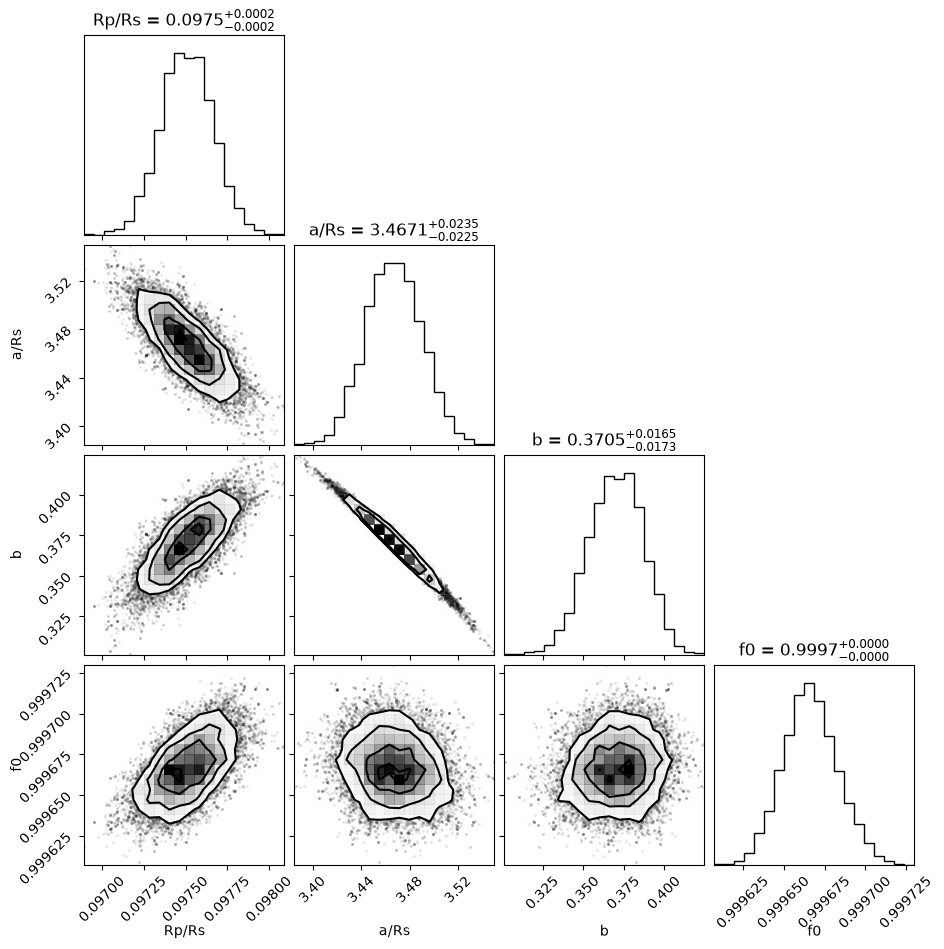

In [20]:
import os
os.makedirs("figures", exist_ok=True)
med = np.median(flat, axis=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(xb * 24, yb, yerr=eb2, fmt=".", color="gray", label="TESS Sector 2 (1-min bins)")
ax.plot(xs_plot * 24, model_f0(xs_plot, *med), color="red", label="Transit model (MCMC median)")
ax.set_xlim(-1.7, 1.7); ax.set_xlabel("Time from mid-transit [h]"); ax.set_ylabel("Normalised flux")
ax.legend(); fig.savefig("figures/transit_fit.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
oc = (times - (T0_new + P_new * epochs)) * 24 * 60
ax.errorbar(epochs, oc, yerr=errs * 24 * 60, fmt="o"); ax.axhline(0, color="red")
ax.set_xlabel("Transit number"); ax.set_ylabel("O − C [min]")
fig.savefig("figures/o_minus_c.png", dpi=150, bbox_inches="tight"); plt.show()

fig = corner.corner(flat, labels=["Rp/Rs", "a/Rs", "b", "f0"], show_titles=True, title_fmt=".4f")
fig.savefig("figures/corner.png", dpi=120, bbox_inches="tight"); plt.show()

In [21]:
lcs = lk.search_lightcurve("WASP-18", mission="TESS", author="SPOC", exptime=120, sector=[2, 3]).download_all()
lc23 = lcs.stitch().remove_nans()
t3 = arr(lc23.time)
m3 = np.abs((t3 - T0_new + P_new/2) % P_new - P_new/2) < 0.075
lc23f = lc23.flatten(window_length=901, mask=m3)
t3, f3, e3 = arr(lc23f.time), arr(lc23f.flux), arr(lc23f.flux_err)
ok = np.isfinite(f3); t3, f3, e3 = t3[ok], f3[ok], e3[ok]
ph3 = (t3 - T0_new + P_new/2) % P_new - P_new/2
s = np.abs(ph3) < 0.07; p_, f_, e_ = ph3[s], f3[s], e3[s]
idx = np.digitize(p_, edges) - 1
xb3, yb3, eb3 = [], [], []
for j in range(len(edges) - 1):
    q = idx == j
    if q.sum() >= 3:
        xb3.append(p_[q].mean()); yb3.append(f_[q].mean()); eb3.append(np.sqrt(np.sum(e_[q]**2)) / q.sum())
xb3, yb3, eb3 = np.array(xb3), np.array(yb3), np.array(eb3)

p3, _ = curve_fit(model_f0, xb3, yb3, p0=popt4, sigma=eb3, absolute_sigma=True,
                  bounds=([0.05, 1.5, 0.0, 0.99], [0.20, 10.0, 1.0, 1.01]))
eb3 = eb3 * np.sqrt(np.sum(((yb3 - model_f0(xb3, *p3)) / eb3)**2) / (len(xb3) - 4))

def log_prob3(th):
    k, a, b, f0 = th
    if not (0.05 < k < 0.2 and 1.5 < a < 10 and 0 <= b < 1 and 0.99 < f0 < 1.01):
        return -np.inf
    return -0.5 * np.sum(((yb3 - model_f0(xb3, *th)) / eb3)**2)

s3 = emcee.EnsembleSampler(24, 4, log_prob3)
s3.run_mcmc(p3 + 1e-5 * np.random.randn(24, 4), 1500, progress=True)
flat3 = s3.get_chain(discard=500, flat=True)
pub = {"Rp/Rs": (0.09716, 0.00014), "a/Rs": (3.562, 0.022), "b": (0.318, 0.019)}
for i, nm in enumerate(["Rp/Rs", "a/Rs", "b"]):
    lo, md, hi = np.percentile(flat3[:, i], [16, 50, 84])
    sig = abs(md - pub[nm][0]) / np.hypot((hi - lo) / 2, pub[nm][1])
    print(f"{nm:6s} = {md:.5f} ± {(hi - lo)/2:.5f}   απόσταση από Shporer: {sig:.1f}σ")

100%|██████████| 1500/1500 [01:07<00:00, 22.29it/s]


Rp/Rs  = 0.09752 ± 0.00014   απόσταση από Shporer: 1.8σ
a/Rs   = 3.48330 ± 0.02219   απόσταση από Shporer: 2.5σ
b      = 0.35915 ± 0.01665   απόσταση από Shporer: 1.6σ
